# **EN3160 – Assignment 3: Neural Networks**

**Student Name:** Saruka U.

**Index Number:** 230585C

**GitHub Repository:** https://github.com/Saruka03/EN3160-Assignment-03

### **Setup**

In [18]:
import os
import random
import time
import copy
import urllib.request
import zipfile

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Device: cpu


### **Helper Functions**

In [4]:
def evaluate(model, loader, criterion=None):
    criterion = criterion or nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, 100.0 * correct / total


def fit(model, name, train_loader, test_loader, optimizer,
        epochs=10, scheduler=None, eval_train=True):
    criterion = nn.CrossEntropyLoss()
    model.to(device)
    history = {k: [] for k in ["train_loss", "train_acc", "test_loss", "test_acc"]}
    start = time.time()

    for epoch in range(epochs):
        model.train()
        run_loss, run_correct, seen = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * y.size(0)
            run_correct += (out.argmax(dim=1) == y).sum().item()
            seen += y.size(0)
        if scheduler is not None:
            scheduler.step()

        if eval_train:
            tr_loss, tr_acc = evaluate(model, train_loader, criterion)
        else:
            tr_loss, tr_acc = run_loss / seen, 100.0 * run_correct / seen
        te_loss, te_acc = evaluate(model, test_loader, criterion)

        for k, v in zip(history, [tr_loss, tr_acc, te_loss, te_acc]):
            history[k].append(v)

        print(f"{name} | Epoch {epoch + 1:02d}/{epochs} | "
              f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.2f}% | "
              f"Test Loss: {te_loss:.4f} | Test Acc: {te_acc:.2f}%")

    history["time_min"] = (time.time() - start) / 60
    print(f"{name}: training time {history['time_min']:.2f} min")
    return model, history


def plot_history(h, title, test_label="Test"):
    ep = range(1, len(h["train_acc"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, key, ylabel in [(axes[0], "loss", "Cross-entropy loss"),
                            (axes[1], "acc", "Accuracy (%)")]:
        ax.plot(ep, h[f"train_{key}"], marker="o", label="Training")
        ax.plot(ep, h[f"test_{key}"], marker="s", label=test_label)
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
        ax.set_title(f"{title}: {ylabel.split()[-1].capitalize()}")
        ax.legend(); ax.grid(True)
    plt.tight_layout(); plt.show()


def compare_histories(hists, test_label="Test"):
    ep = range(1, len(next(iter(hists.values()))["train_acc"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for (name, h), marker in zip(hists.items(), ["o", "s", "^"]):
        for ax, key in [(axes[0], "acc"), (axes[1], "loss")]:
            line, = ax.plot(ep, h[f"train_{key}"], marker=marker, label=f"{name} train")
            ax.plot(ep, h[f"test_{key}"], marker=marker, linestyle="--",
                    color=line.get_color(), label=f"{name} {test_label.lower()}")
    axes[0].set_title("Accuracy comparison"); axes[0].set_ylabel("Accuracy (%)")
    axes[1].set_title("Loss comparison"); axes[1].set_ylabel("Cross-entropy loss")
    for ax in axes:
        ax.set_xlabel("Epoch"); ax.legend(); ax.grid(True)
    plt.tight_layout(); plt.show()


def summary_row(name, h):
    return {"Model": name,
            "Final train acc (%)": h["train_acc"][-1],
            "Final test acc (%)": h["test_acc"][-1],
            "Best test acc (%)": max(h["test_acc"]),
            "Final train loss": h["train_loss"][-1],
            "Final test loss": h["test_loss"][-1],
            "Time (min)": h["time_min"]}

### **Task 1: Manually Implemented Dense Neural Network**
#### Objective

The objective is to modify the provided dense neural network for CIFAR-10 image classification. A hidden layer containing 100 neurons with sigmoid activation is introduced, and the network is trained using cross-entropy loss.

#### 1.1 Dataset and preprocessing

In [5]:
# CIFAR-10 preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5))])

batch_size = 100

trainset = torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
testset = torchvision.datasets.CIFAR10(root="./data",train=False,download=True,transform=transform)
trainloader = DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=0)
testloader = DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=0)

classes = ("plane", "car", "bird", "cat", "deer","dog", "frog", "horse", "ship", "truck")

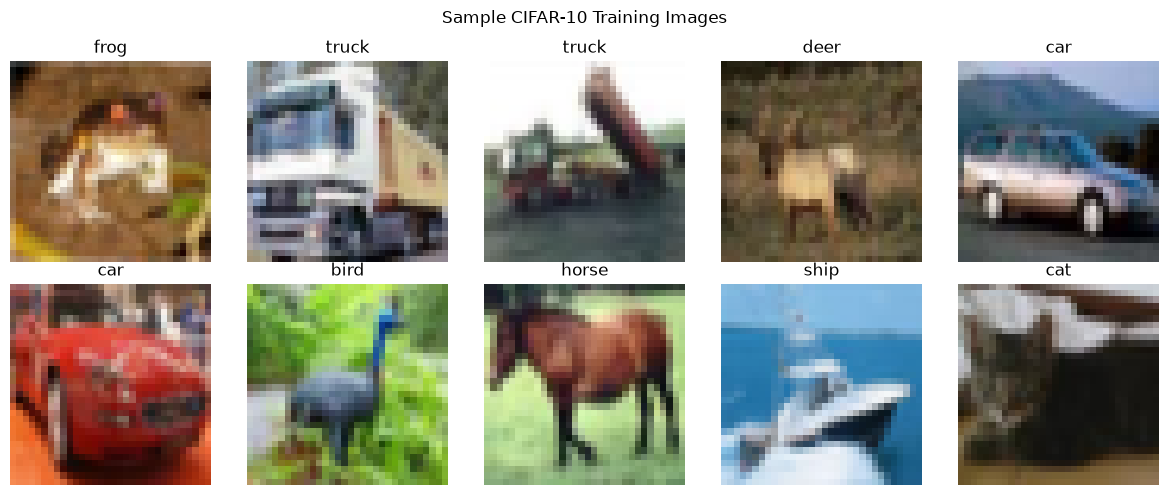

In [6]:
def show_cifar_samples(dataset, classes, count=10):
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))

    for i, ax in enumerate(axes.flat):
        image, label = dataset[i]

        # Undo normalization for display
        image = image * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()

        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(classes[label])
        ax.axis("off")

    plt.suptitle("Sample CIFAR-10 Training Images")
    plt.tight_layout()
    plt.show()

show_cifar_samples(trainset, classes)

### 1.2 Network parameters and hyperparameters

In [7]:
Din = 3 * 32 * 32
H = 100
K = 10

# Hyperparameters
epochs = 10
learning_rate = 0.01
learning_rate_decay = 0.95

# Xavier-style initialization for sigmoid hidden units
W1 = torch.randn(Din, H, device=device) * np.sqrt(1.0 / Din)
b1 = torch.zeros(H, device=device)
W2 = torch.randn(H, K, device=device) * np.sqrt(1.0 / H)
b2 = torch.zeros(K, device=device)

### 1.3 Forward pass, loss and manual backpropagation

In [8]:
def forward_pass(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = torch.sigmoid(Z1)          # hidden layer
    Z2 = A1 @ W2 + b2               # output layer: logits
    return A1, Z2


def cross_entropy_loss(logits, labels):
    log_probs = F.log_softmax(logits, dim=1)
    return -log_probs[torch.arange(labels.shape[0], device=labels.device), labels].mean()


def manual_backprop(X, labels, W1, b1, W2, b2):
    N = X.shape[0]
    A1, logits = forward_pass(X, W1, b1, W2, b2)
    loss = cross_entropy_loss(logits, labels)

    dZ2 = F.softmax(logits, dim=1)
    dZ2[torch.arange(N, device=labels.device), labels] -= 1.0
    dZ2 /= N

    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(dim=0)
    dZ1 = (dZ2 @ W2.T) * A1 * (1.0 - A1)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(dim=0)
    return loss, (dW1, db1, dW2, db2)


def evaluate_manual_network(loader, W1, b1, W2, b2):
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            labels = labels.to(device)
            X = images.to(device).reshape(images.shape[0], -1)
            _, logits = forward_pass(X, W1, b1, W2, b2)
            total_loss += cross_entropy_loss(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

### 1.4 Training for 10 epochs

In [9]:
task1_history = {k: [] for k in ["train_loss", "train_acc", "test_loss", "test_acc"]}
iteration_loss = []
lr = learning_rate
start = time.time()

for epoch in range(epochs):
    for images, labels in trainloader:
        labels = labels.to(device)
        X = images.to(device).reshape(images.shape[0], -1)

        loss, (dW1, db1, dW2, db2) = manual_backprop(X, labels, W1, b1, W2, b2)

        with torch.no_grad():                       # manual gradient-descent update
            W1 -= lr * dW1;  b1 -= lr * db1
            W2 -= lr * dW2;  b2 -= lr * db2
        iteration_loss.append(loss.item())

    tr_loss, tr_acc = evaluate_manual_network(trainloader, W1, b1, W2, b2)
    te_loss, te_acc = evaluate_manual_network(testloader, W1, b1, W2, b2)
    for k, v in zip(task1_history, [tr_loss, tr_acc, te_loss, te_acc]):
        task1_history[k].append(v)

    print(f"Epoch {epoch + 1:02d}/{epochs} | Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.2f}% | "
          f"Test Loss: {te_loss:.4f} | Test Acc: {te_acc:.2f}%")
    lr *= learning_rate_decay

task1_history["time_min"] = (time.time() - start) / 60
print(f"\nTotal training time: {task1_history['time_min']:.2f} minutes")

Epoch 01/10 | Train Loss: 1.9754 | Train Acc: 32.98% | Test Loss: 1.9735 | Test Acc: 33.04%
Epoch 02/10 | Train Loss: 1.8947 | Train Acc: 35.52% | Test Loss: 1.8946 | Test Acc: 35.24%
Epoch 03/10 | Train Loss: 1.8539 | Train Acc: 36.35% | Test Loss: 1.8549 | Test Acc: 35.88%
Epoch 04/10 | Train Loss: 1.8266 | Train Acc: 37.41% | Test Loss: 1.8285 | Test Acc: 36.79%
Epoch 05/10 | Train Loss: 1.8070 | Train Acc: 38.13% | Test Loss: 1.8093 | Test Acc: 37.64%
Epoch 06/10 | Train Loss: 1.7918 | Train Acc: 38.51% | Test Loss: 1.7953 | Test Acc: 38.20%
Epoch 07/10 | Train Loss: 1.7791 | Train Acc: 38.83% | Test Loss: 1.7827 | Test Acc: 38.66%
Epoch 08/10 | Train Loss: 1.7687 | Train Acc: 39.24% | Test Loss: 1.7727 | Test Acc: 39.25%
Epoch 09/10 | Train Loss: 1.7601 | Train Acc: 39.53% | Test Loss: 1.7643 | Test Acc: 39.18%
Epoch 10/10 | Train Loss: 1.7519 | Train Acc: 39.71% | Test Loss: 1.7566 | Test Acc: 39.71%

Total training time: 3.48 minutes


### 1.5 Results

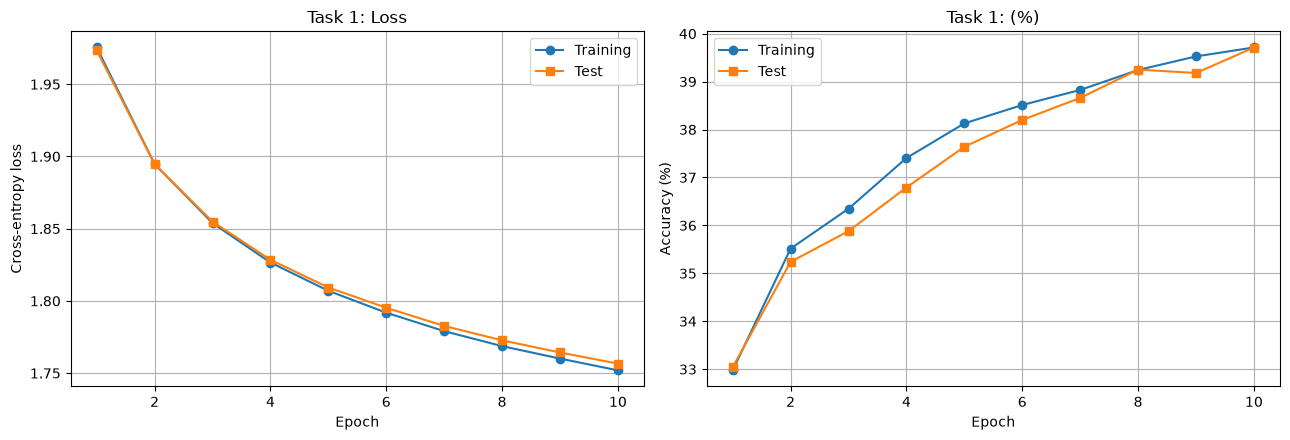

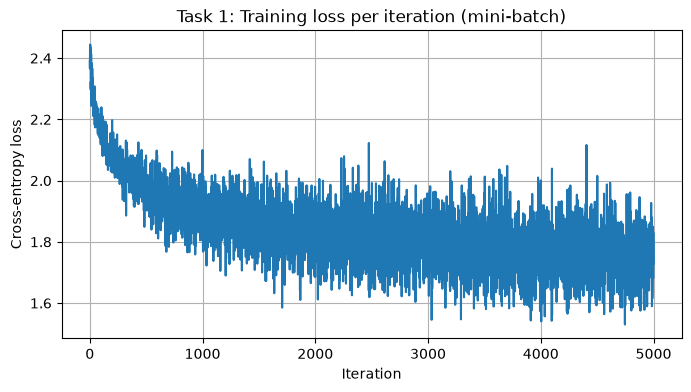

,Metric,Value
0,Training accuracy (%),39.71
1,Test accuracy (%),39.71


In [10]:
plot_history(task1_history, "Task 1")

plt.figure(figsize=(8, 4))
plt.plot(iteration_loss)
plt.title("Task 1: Training loss per iteration (mini-batch)")
plt.xlabel("Iteration"); plt.ylabel("Cross-entropy loss"); plt.grid(True)
plt.show()

display(pd.DataFrame({
    "Metric": ["Training accuracy (%)", "Test accuracy (%)"],
    "Value": [task1_history["train_acc"][-1], task1_history["test_acc"][-1]]
}).round(2))

### **Task 1 Discussion**

After 10 epochs the network reaches **39.71 % training accuracy and 39.71 % test accuracy** (test loss ≈ 1.76), well above the 10 % chance level but low in absolute terms.

- **Underfitting, not overfitting.** The training and test curves almost coincide, so the limit is model capacity, not generalization.
- **Not yet converged.** The loss was still falling at epoch 10 (1.98 → 1.75), so more epochs or a larger learning rate would still help.
- **Why accuracy is limited.** Flattening each image discards its spatial structure, and one hidden layer of 100 sigmoid units can only learn simple global patterns. Convolutional networks are designed to avoid this limitation.

*Note:* Task 1 uses CIFAR-10 and Task 2 uses MNIST, so their accuracies cannot be compared directly.

### **Task 2: CNN Architectures for MNIST Classification**

#### Objective

This task evaluates two convolutional neural network architectures on the MNIST handwritten-digit dataset. Both models are trained for ten epochs, and their training and test accuracy and loss are recorded.

The first model is LeNet-5, a classic CNN architecture. The second is a modern three-layer CNN incorporating batch normalization and dropout. Their performance is compared using learning curves, final accuracy measurements, and confusion matrices on the test set.

MNIST training images: 60000
MNIST test images: 10000
Image shape: torch.Size([1, 28, 28])


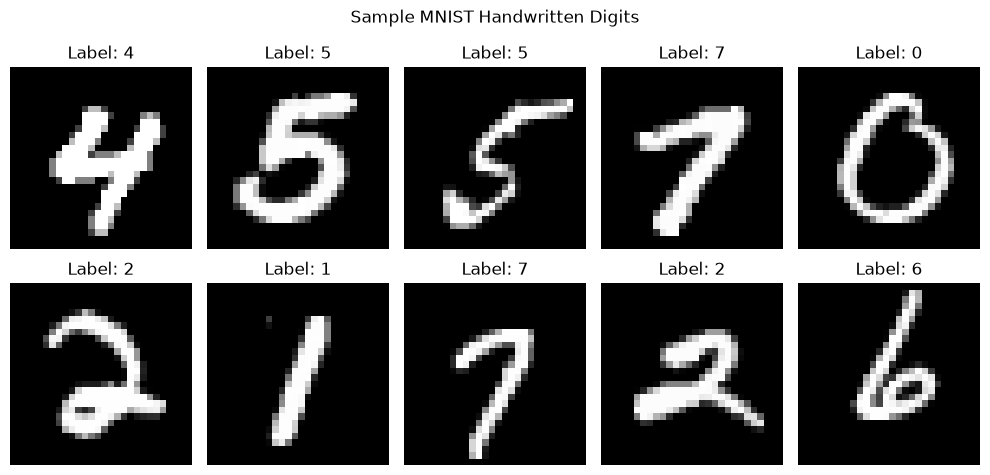

In [11]:
batch_size_mnist = 128

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])

trainset_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=mnist_transform)
testset_mnist = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=mnist_transform)
trainloader_mnist = DataLoader(trainset_mnist, batch_size=batch_size_mnist, shuffle=True, num_workers=0)
testloader_mnist = DataLoader(testset_mnist, batch_size=batch_size_mnist, shuffle=False, num_workers=0)

print("MNIST training images:", len(trainset_mnist))
print("MNIST test images:", len(testset_mnist))
print("Image shape:", trainset_mnist[0][0].shape)

# Sample images
images, labels = next(iter(trainloader_mnist))
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0] * 0.3081 + 0.1307, cmap="gray")   # undo normalization
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")
plt.suptitle("Sample MNIST Handwritten Digits")
plt.tight_layout()
plt.show()

### 2.1 Model definitions

In [12]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.AvgPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.AvgPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(torch.tanh(self.conv1(x)))
        x = self.pool2(torch.tanh(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)


class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1, self.bn1 = nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32)
        self.conv2, self.bn2 = nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64)
        self.conv3, self.bn3 = nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout_conv = nn.Dropout2d(0.25)
        self.dropout_fc = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 * 3 * 3, 128)    # 28 -> 14 -> 7 -> 3
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.dropout_conv(x)
        x = torch.flatten(x, 1)
        x = self.dropout_fc(F.relu(self.fc1(x)))
        return self.fc2(x)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print("LeNet-5 parameters:   ", f"{count_params(LeNet5()):,}")
print("Modern CNN parameters:", f"{count_params(ModernCNN()):,}")

LeNet-5 parameters:    44,426
Modern CNN parameters: 241,994


### 2.2 Task 2(a): Train LeNet-5

LeNet-5 | Epoch 01/10 | Train Loss: 0.1083 | Train Acc: 96.79% | Test Loss: 0.1035 | Test Acc: 97.03%
LeNet-5 | Epoch 02/10 | Train Loss: 0.0637 | Train Acc: 98.09% | Test Loss: 0.0688 | Test Acc: 97.88%
LeNet-5 | Epoch 03/10 | Train Loss: 0.0465 | Train Acc: 98.59% | Test Loss: 0.0494 | Test Acc: 98.44%
LeNet-5 | Epoch 04/10 | Train Loss: 0.0351 | Train Acc: 98.94% | Test Loss: 0.0435 | Test Acc: 98.57%
LeNet-5 | Epoch 05/10 | Train Loss: 0.0357 | Train Acc: 98.86% | Test Loss: 0.0451 | Test Acc: 98.52%
LeNet-5 | Epoch 06/10 | Train Loss: 0.0241 | Train Acc: 99.27% | Test Loss: 0.0381 | Test Acc: 98.78%
LeNet-5 | Epoch 07/10 | Train Loss: 0.0272 | Train Acc: 99.16% | Test Loss: 0.0376 | Test Acc: 98.74%
LeNet-5 | Epoch 08/10 | Train Loss: 0.0182 | Train Acc: 99.49% | Test Loss: 0.0317 | Test Acc: 98.97%
LeNet-5 | Epoch 09/10 | Train Loss: 0.0192 | Train Acc: 99.41% | Test Loss: 0.0404 | Test Acc: 98.88%
LeNet-5 | Epoch 10/10 | Train Loss: 0.0207 | Train Acc: 99.31% | Test Loss: 0.0421

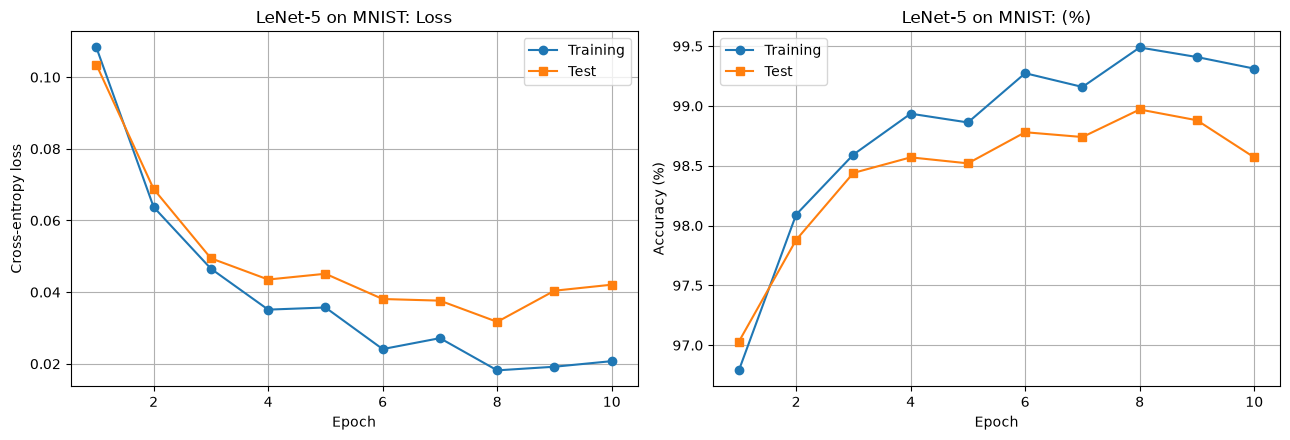

In [13]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
lenet_model = LeNet5()
opt = optim.Adam(lenet_model.parameters(), lr=0.001)
lenet_model, hist_lenet = fit(lenet_model, "LeNet-5", trainloader_mnist, testloader_mnist, opt, epochs=10)
plot_history(hist_lenet, "LeNet-5 on MNIST")

### 2.3 Task 2(b): Train the modern CNN

Modern CNN | Epoch 01/10 | Train Loss: 0.0477 | Train Acc: 98.52% | Test Loss: 0.0467 | Test Acc: 98.48%
Modern CNN | Epoch 02/10 | Train Loss: 0.0291 | Train Acc: 99.08% | Test Loss: 0.0278 | Test Acc: 99.09%
Modern CNN | Epoch 03/10 | Train Loss: 0.0234 | Train Acc: 99.27% | Test Loss: 0.0299 | Test Acc: 99.04%
Modern CNN | Epoch 04/10 | Train Loss: 0.0221 | Train Acc: 99.30% | Test Loss: 0.0321 | Test Acc: 98.96%
Modern CNN | Epoch 05/10 | Train Loss: 0.0145 | Train Acc: 99.55% | Test Loss: 0.0230 | Test Acc: 99.35%
Modern CNN | Epoch 06/10 | Train Loss: 0.0166 | Train Acc: 99.47% | Test Loss: 0.0293 | Test Acc: 99.06%
Modern CNN | Epoch 07/10 | Train Loss: 0.0095 | Train Acc: 99.68% | Test Loss: 0.0199 | Test Acc: 99.40%
Modern CNN | Epoch 08/10 | Train Loss: 0.0089 | Train Acc: 99.71% | Test Loss: 0.0239 | Test Acc: 99.32%
Modern CNN | Epoch 09/10 | Train Loss: 0.0064 | Train Acc: 99.80% | Test Loss: 0.0205 | Test Acc: 99.27%
Modern CNN | Epoch 10/10 | Train Loss: 0.0050 | Train A

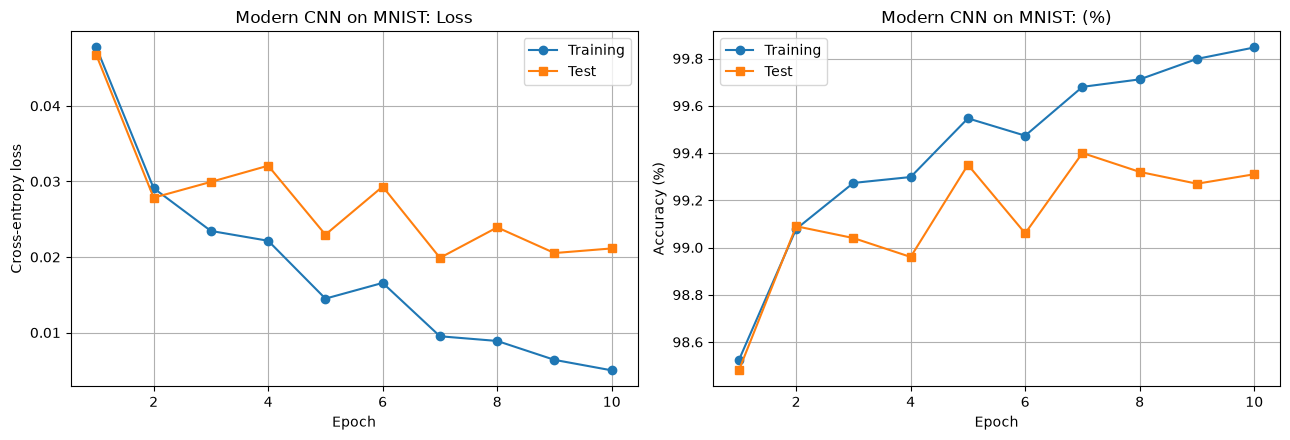

In [14]:
set_seed()
modern_model = ModernCNN()
opt = optim.Adam(modern_model.parameters(), lr=0.001)
modern_model, hist_modern = fit(modern_model, "Modern CNN", trainloader_mnist, testloader_mnist, opt, epochs=10)
plot_history(hist_modern, "Modern CNN on MNIST")

### 2.4 Task 2(c): Comparison of the two models

,Model,Final train acc (%),Final test acc (%),Best test acc (%),Final train loss,Final test loss,Time (min)
0,LeNet-5,99.3117,98.57,98.97,0.0207,0.0421,7.6483
1,Modern CNN,99.8467,99.31,99.40,0.0050,0.0211,17.0506


Final-epoch test accuracy difference (Modern CNN - LeNet-5): 0.74 percentage points (~74 of 10000 test images)


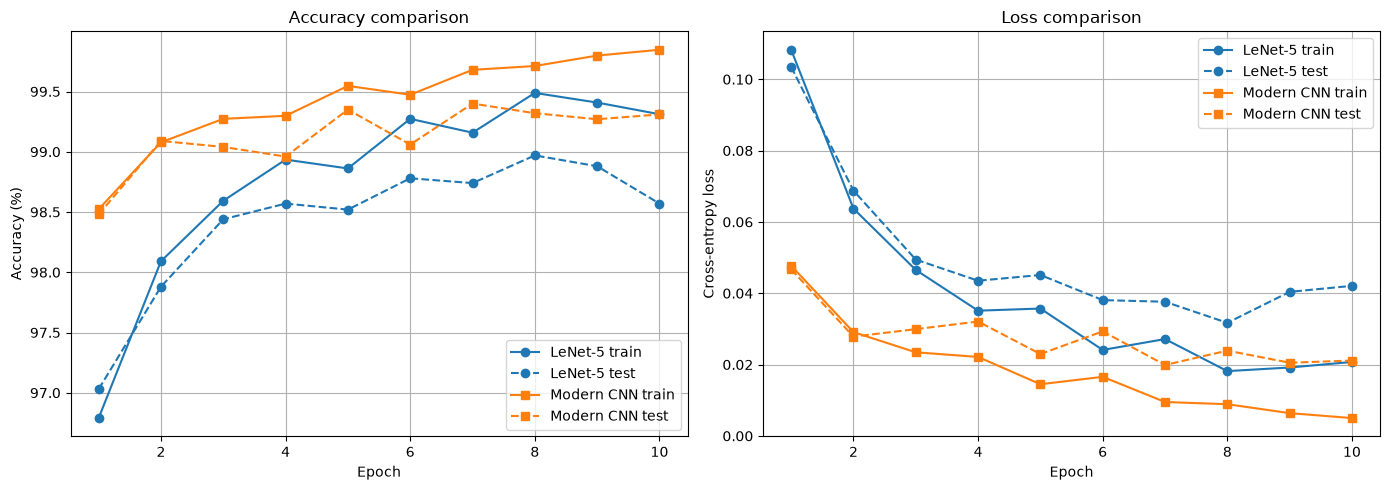

In [15]:
mnist_summary = pd.DataFrame([summary_row("LeNet-5", hist_lenet),
                              summary_row("Modern CNN", hist_modern)])
display(mnist_summary.round(4))

gain = hist_modern["test_acc"][-1] - hist_lenet["test_acc"][-1]
print(f"Final-epoch test accuracy difference (Modern CNN - LeNet-5): {gain:.2f} percentage points "
      f"(~{gain / 100 * len(testset_mnist):.0f} of {len(testset_mnist)} test images)")

compare_histories({"LeNet-5": hist_lenet, "Modern CNN": hist_modern})

### 2.5 Confusion matrices on the test set

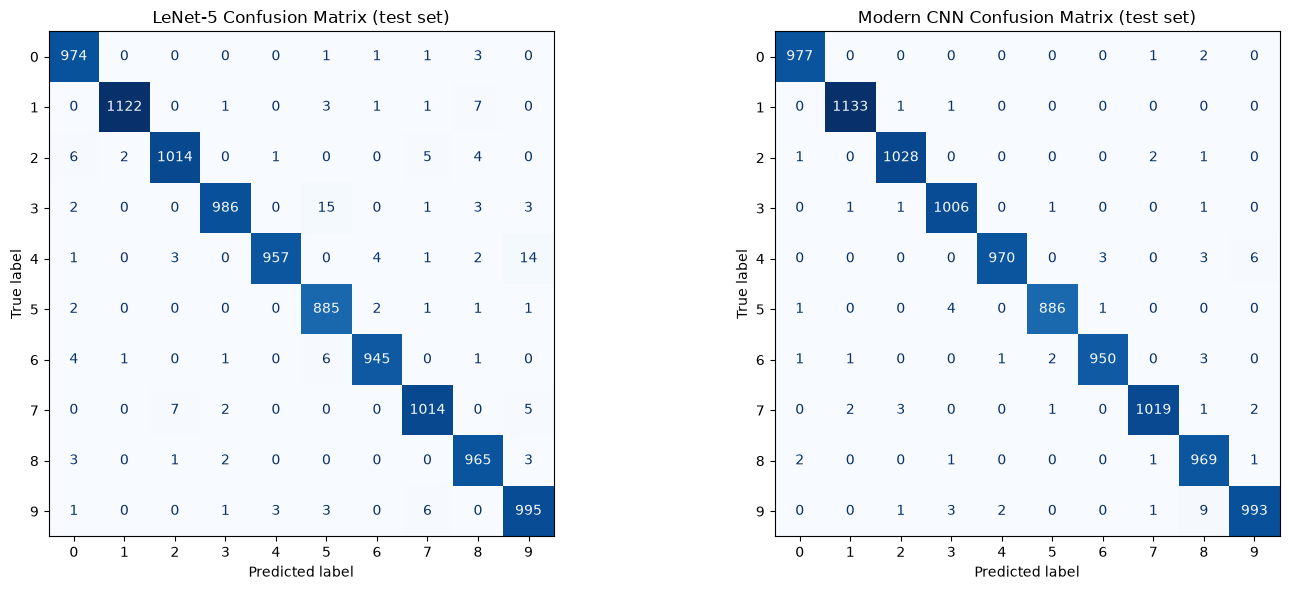


Most frequent confusions - LeNet-5


,True digit,Predicted as,Count
0,3,5,15
1,4,9,14
2,1,8,7
3,7,2,7
4,6,5,6



Most frequent confusions - Modern CNN


,True digit,Predicted as,Count
0,9,8,9
1,4,9,6
2,5,3,4
3,4,8,3
4,7,2,3


In [16]:
def get_predictions(model, loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x, y in loader:
            preds.append(model(x.to(device)).argmax(dim=1).cpu())
            trues.append(y)
    return torch.cat(trues).numpy(), torch.cat(preds).numpy()


def top_confusions(cm, n=5):
    off = cm.copy()
    np.fill_diagonal(off, 0)
    order = np.argsort(-off.ravel())[:n]
    rows = [(i, j, off[i, j]) for i, j in zip(*np.unravel_index(order, off.shape))]
    return pd.DataFrame(rows, columns=["True digit", "Predicted as", "Count"])


digits = list(range(10))
cms = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, model) in zip(axes, [("LeNet-5", lenet_model), ("Modern CNN", modern_model)]):
    y_true, y_pred = get_predictions(model, testloader_mnist)
    cms[name] = confusion_matrix(y_true, y_pred, labels=digits)
    ConfusionMatrixDisplay(cms[name], display_labels=digits).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} Confusion Matrix (test set)")
plt.tight_layout()
plt.show()

for name, cm in cms.items():
    print(f"\nMost frequent confusions - {name}")
    display(top_confusions(cm))

### **Task 2 Discussion**

| Model | Parameters | Final train acc | Final test acc | Train–test gap | Best test acc | Final test loss | Time |
|---|---|---|---|---|---|---|---|
| LeNet-5 | 44,426 | 99.31 % | 98.57 % | 0.74 | 98.97 % (epoch 8) | 0.0421 | 7.65 min |
| Modern CNN | 241,994 | 99.85 % | 99.31 % | 0.54 | 99.40 % (epoch 7) | 0.0211 | 17.05 min |

- **The modern CNN is better.** Its final test accuracy is 0.74 points higher (143 vs. 69 misclassified images), and it was ahead at every one of the 10 epochs. It also learns faster (98.48 % after epoch 1 vs. 97.03 %) and has half the test loss. This is a single run with one seed, and the models differ in several ways at once (activation, pooling, depth, batch normalization, dropout), so the gain cannot be credited to any one component.
- **Stability.** Test accuracy fluctuates for both models. LeNet-5 peaked at epoch 8 (98.97 %) and fell to 98.57 % by epoch 10. The modern CNN stayed close to its peak (99.40 % → 99.31 %).
- **Cost.** The modern CNN has about 5.4× more parameters and took about 2.2× longer to train.
- **Confusion matrices.** Both are strongly diagonal. LeNet-5's main errors are 3→5 (15) and 4→9 (14). The modern CNN roughly halves 4→9 (6) and 7→2 (3), but its largest error is 9→8 (9). The 4/9 pair remains a source of error for both.

# **Task 3: Transfer Learning with ResNet18**
#### Objective

Use a ResNet18 pretrained on ImageNet-1K to classify the Hymenoptera dataset (ants vs. bees) following the PyTorch transfer-learning tutorial, with two strategies:

1. **Fine-tuning** – all layers are initialized from the pretrained weights and **all** parameters are trained, with a new 2-class output layer.
2. **Feature extraction** – the pretrained backbone is **frozen** and only the new 2-class output layer is trained.

Hymenoptera dataset already exists.
Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


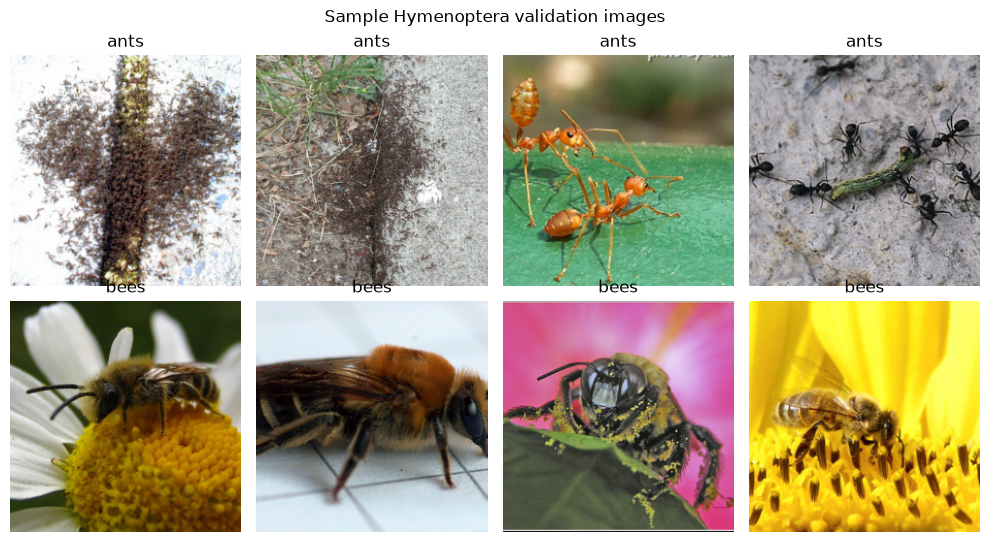

In [20]:
data_dir = "./data"
dataset_dir = os.path.join(data_dir, "hymenoptera_data")
zip_path = os.path.join(data_dir, "hymenoptera_data.zip")

if not os.path.exists(dataset_dir):
    print("Downloading Hymenoptera dataset...")
    urllib.request.urlretrieve("https://download.pytorch.org/tutorial/hymenoptera_data.zip", zip_path)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(data_dir)
    print("Dataset extracted.")
else:
    print("Hymenoptera dataset already exists.")

imagenet_norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
data_transforms = {
    "train": transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
                                 transforms.ToTensor(), imagenet_norm]),
    "val": transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                               transforms.ToTensor(), imagenet_norm]),
}

image_datasets = {
    s: torchvision.datasets.ImageFolder(
        os.path.join(dataset_dir, s),
        transform=data_transforms[s]
    )
    for s in ["train", "val"]
}
dataloaders = {s: DataLoader(image_datasets[s], batch_size=16, shuffle=(s == "train"), num_workers=0)
               for s in ["train", "val"]}
class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Training images:", len(image_datasets["train"]))
print("Validation images:", len(image_datasets["val"]))

# Sample validation images
idx = np.linspace(0, len(image_datasets["val"]) - 1, 8).astype(int)
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for ax, i in zip(axes.flat, idx):
    img, lab = image_datasets["val"][i]
    ax.imshow(np.clip(img.permute(1, 2, 0).numpy() * std + mean, 0, 1))
    ax.set_title(class_names[lab]); ax.axis("off")
plt.suptitle("Sample Hymenoptera validation images")
plt.tight_layout(); plt.show()

### 3.1 Building the two models

In [22]:
def build_resnet18(freeze_backbone):
    model = torchvision.models.resnet18(
        weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1
    )
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 2)      # new layer is always trainable
    return model.to(device)

epochs_t3 = 10
print("Trainable parameters - fine-tuning:       ", f"{count_params(build_resnet18(False)):,}")
print("Trainable parameters - feature extraction:", f"{count_params(build_resnet18(True)):,}")

Trainable parameters - fine-tuning:        11,177,538
Trainable parameters - feature extraction: 1,026


### 3.2 Task 3(a): Fine-tuning

In [23]:
set_seed()
model_ft = build_resnet18(freeze_backbone=False)
opt = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
sched = optim.lr_scheduler.StepLR(opt, step_size=7, gamma=0.1)
model_ft, hist_ft = fit(model_ft, "Fine-tuning", dataloaders["train"], dataloaders["val"], opt,
                        epochs=epochs_t3, scheduler=sched, eval_train=False)

Fine-tuning | Epoch 01/10 | Train Loss: 0.5454 | Train Acc: 75.41% | Test Loss: 0.2943 | Test Acc: 93.46%
Fine-tuning | Epoch 02/10 | Train Loss: 0.3196 | Train Acc: 84.43% | Test Loss: 0.2138 | Test Acc: 91.50%
Fine-tuning | Epoch 03/10 | Train Loss: 0.2678 | Train Acc: 88.52% | Test Loss: 0.1779 | Test Acc: 94.77%
Fine-tuning | Epoch 04/10 | Train Loss: 0.1914 | Train Acc: 93.03% | Test Loss: 0.1666 | Test Acc: 92.81%
Fine-tuning | Epoch 05/10 | Train Loss: 0.1562 | Train Acc: 94.26% | Test Loss: 0.1673 | Test Acc: 93.46%
Fine-tuning | Epoch 06/10 | Train Loss: 0.1377 | Train Acc: 95.08% | Test Loss: 0.1551 | Test Acc: 94.12%
Fine-tuning | Epoch 07/10 | Train Loss: 0.2659 | Train Acc: 88.93% | Test Loss: 0.1550 | Test Acc: 94.12%
Fine-tuning | Epoch 08/10 | Train Loss: 0.0998 | Train Acc: 97.13% | Test Loss: 0.1655 | Test Acc: 92.81%
Fine-tuning | Epoch 09/10 | Train Loss: 0.1587 | Train Acc: 93.44% | Test Loss: 0.1774 | Test Acc: 92.16%
Fine-tuning | Epoch 10/10 | Train Loss: 0.1286

### 3.3 Task 3(b): ResNet18 as a fixed feature extractor

In [24]:
set_seed()
model_fe = build_resnet18(freeze_backbone=True)
opt = optim.SGD(model_fe.fc.parameters(), lr=0.001, momentum=0.9)
sched = optim.lr_scheduler.StepLR(opt, step_size=7, gamma=0.1)
model_fe, hist_fe = fit(model_fe, "Feature extraction", dataloaders["train"], dataloaders["val"], opt,
                        epochs=epochs_t3, scheduler=sched, eval_train=False)

Feature extraction | Epoch 01/10 | Train Loss: 0.5899 | Train Acc: 68.03% | Test Loss: 0.3890 | Test Acc: 90.20%
Feature extraction | Epoch 02/10 | Train Loss: 0.4075 | Train Acc: 83.20% | Test Loss: 0.3420 | Test Acc: 84.97%
Feature extraction | Epoch 03/10 | Train Loss: 0.3284 | Train Acc: 86.89% | Test Loss: 0.2097 | Test Acc: 94.12%
Feature extraction | Epoch 04/10 | Train Loss: 0.2594 | Train Acc: 90.16% | Test Loss: 0.1998 | Test Acc: 92.81%
Feature extraction | Epoch 05/10 | Train Loss: 0.2498 | Train Acc: 88.93% | Test Loss: 0.2014 | Test Acc: 92.81%
Feature extraction | Epoch 06/10 | Train Loss: 0.2501 | Train Acc: 89.34% | Test Loss: 0.1753 | Test Acc: 95.42%
Feature extraction | Epoch 07/10 | Train Loss: 0.3442 | Train Acc: 84.43% | Test Loss: 0.1629 | Test Acc: 94.77%
Feature extraction | Epoch 08/10 | Train Loss: 0.1861 | Train Acc: 94.26% | Test Loss: 0.1713 | Test Acc: 95.42%
Feature extraction | Epoch 09/10 | Train Loss: 0.2359 | Train Acc: 90.98% | Test Loss: 0.1899 | 

### 3.4 Results and comparison

,Method,Trainable params,Time (min),Final train acc (%),Final val acc (%),Best val acc (%),Best epoch,Final val loss
0,Fine-tuning,11177538,3.984,95.492,94.118,94.771,3,0.158
1,Feature extraction,1026,1.898,90.984,94.771,95.425,6,0.167


Fine-tuning: final val acc = 94.12% (144/153 images correct)
Feature extraction: final val acc = 94.77% (145/153 images correct)


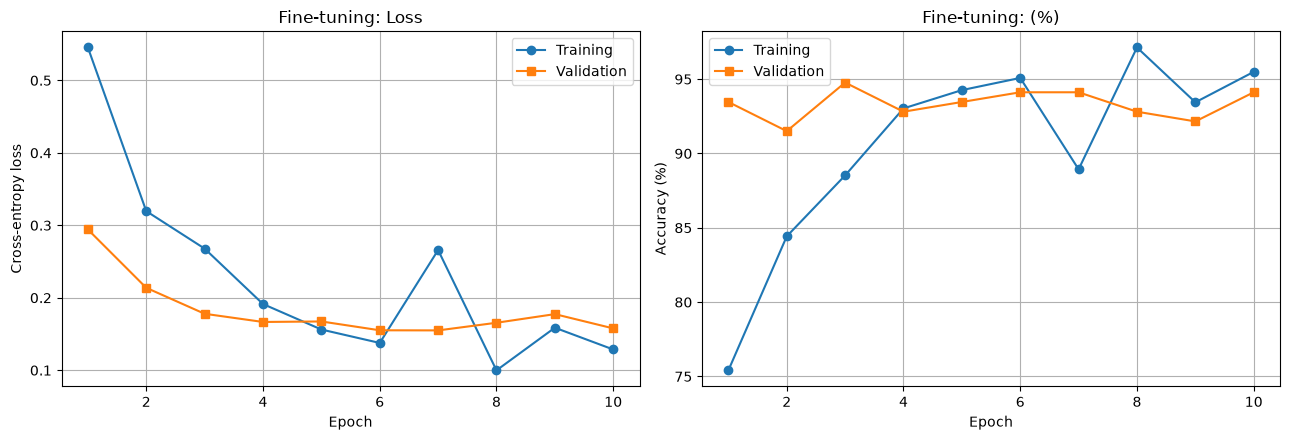

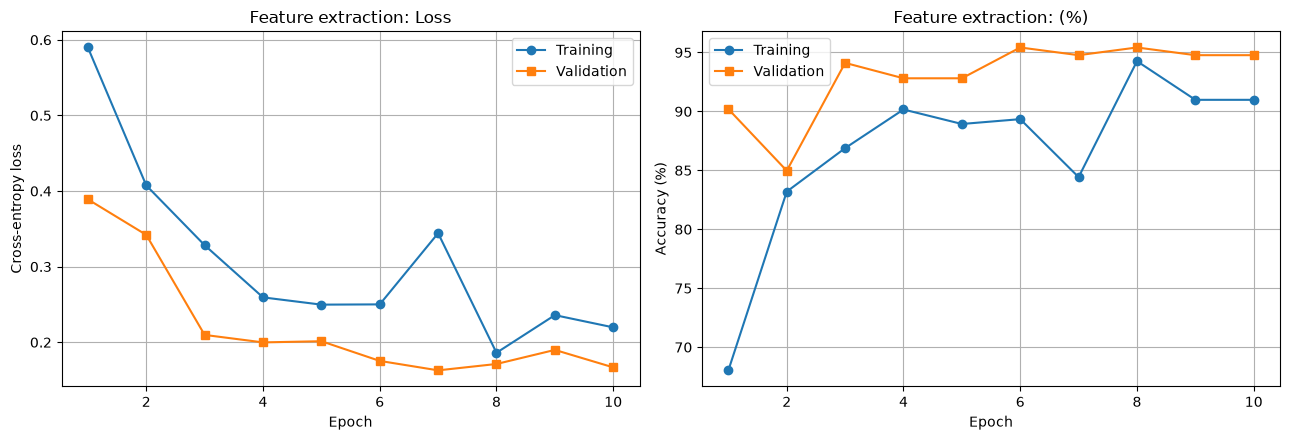

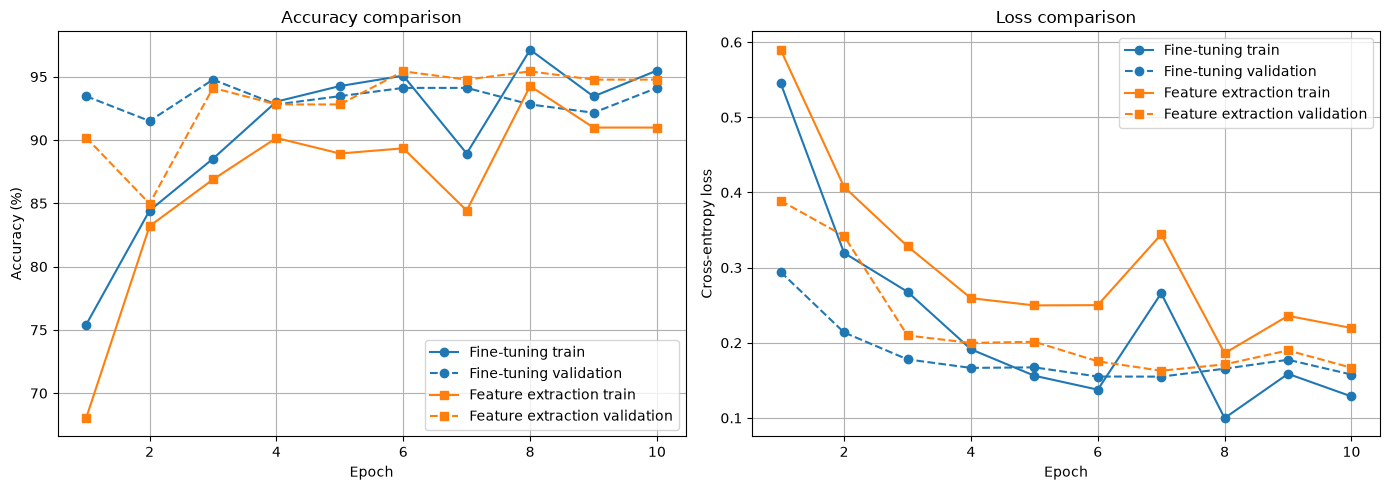

In [25]:
rows = []
for name, h, m in [("Fine-tuning", hist_ft, model_ft), ("Feature extraction", hist_fe, model_fe)]:
    r = summary_row(name, h)
    r["Best epoch"] = int(np.argmax(h["test_acc"])) + 1
    r["Trainable params"] = count_params(m)
    rows.append(r)

t3_summary = pd.DataFrame(rows).rename(columns={
    "Model": "Method", "Final test acc (%)": "Final val acc (%)", "Best test acc (%)": "Best val acc (%)",
    "Final test loss": "Final val loss"})
display(t3_summary[["Method", "Trainable params", "Time (min)", "Final train acc (%)",
                    "Final val acc (%)", "Best val acc (%)", "Best epoch", "Final val loss"]].round(3))

n_val = len(image_datasets["val"])
for name, h in [("Fine-tuning", hist_ft), ("Feature extraction", hist_fe)]:
    print(f"{name}: final val acc = {h['test_acc'][-1]:.2f}% "
          f"({round(h['test_acc'][-1] / 100 * n_val)}/{n_val} images correct)")

plot_history(hist_ft, "Fine-tuning", test_label="Validation")
plot_history(hist_fe, "Feature extraction", test_label="Validation")
compare_histories({"Fine-tuning": hist_ft, "Feature extraction": hist_fe}, test_label="Validation")

### **Task 3 Discussion**

| Method | Trainable params | Time | Final val acc | Best val acc | Final val loss |
|---|---|---|---|---|---|
| Fine-tuning | 11,177,538 | 3.98 min | 94.12 % (144/153) | 94.77 % (epoch 3) | 0.158 |
| Feature extraction | 1,026 | 1.90 min | 94.77 % (145/153) | 95.42 % (epoch 6) | 0.167 |

- **Accuracy is effectively tied.** Feature extraction is ahead by one image of 153 (0.65 points) at both the final and best epoch. This is within noise, so neither method can be declared the winner. The best-epoch values are chosen using the validation set, so the final-epoch values are the fairer estimate.
- **Stability.** Fine-tuning learns faster at first (93.46 % vs. 90.20 % after epoch 1), but its validation accuracy keeps fluctuating (92.2–94.1 % in epochs 8–10). Feature extraction settles at 94.8–95.4 % after the learning-rate drop.
- **Cost.** Feature extraction trains only 1,026 parameters instead of about 11.2 M, and it ran about 2.1× faster.
- **Conclusion.** On this small, ImageNet-like dataset the pretrained features are already strong, so feature extraction gives the same accuracy at about half the cost. This experiment is too small to show whether fine-tuning would give a further gain.

---
### **Overall Conclusions**

- **Task 1.** A manually implemented 3072–100–10 sigmoid network trained with cross-entropy reaches 39.71 % training and 39.71 % test accuracy on CIFAR-10. The two accuracies match, so the limit is model capacity (flattened pixels, one hidden layer), not overfitting.
- **Task 2.** On MNIST, LeNet-5 reaches 98.57 % and the modern CNN 99.31 % test accuracy after 10 epochs. The modern CNN learns faster, has a lower test loss and was higher at every epoch, at about 5.4× the parameters and 2.2× the training time.
- **Task 3.** Fine-tuning (94.12 % final validation accuracy) and feature extraction (94.77 %) differ by one image out of 153. Feature extraction is cheaper (1,026 vs. about 11.2 M trainable parameters, half the time) and steadier late in training.
- **General lesson.** Convolutional structure and pretrained features give large gains over a plain dense network trained from scratch, and small differences between models must be judged against the size of the test set and run-to-run variation.